# Chapter 9: Dimensionality reduction

In [13]:
%reset
low_memory=False
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.mlab as mlab
import seaborn as sns; sns.set()
from scipy import stats
import math
import os
import random
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier

## 9.1 Introduction & Motivation

We've seen quite a few regression, classification and clustering methods. That's great! We can already train a lot of different models and gain insights from them. However, now it's time to take a small step back and look at the data we are feeding our models. Instead of just throwing everything we have at it, we are going to reduce our data by performing **PCA**.

Why do we do this? When working with large dataset, training a model becomes more complex. For example, think of the training process of a GPT model. The more data is being used, the more time it will take to train and the more CPU power it will use, requiring expensive machinery and also driving up the electricity bill like crazy. We do however want to retain most of the information contained in our data. That's where PCA comes into play. We reduce data by reshaping it to a few core components and keeping the information contained within.

## 9.2 Problem setting

The faces dataset is a useful dataset when exploring the differences between models and the effect of dimensionality reduction techniques. This makes it a prime candidate to explore PCA!

Similar to the digits dataset, it contains a bunch of images and labels. This time however, the images are not handwritten digits but faces of famous American politicians. Try to explore the dataset and find out what we can achieve with PCA!

## 9.3 Model

First, let's have a look at the data.

In [14]:
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=60)
X = faces.data
y = faces.target
image_shape = faces.images.shape[1:]

print('Target names:', faces.target_names)
print('Images shape:', faces.images.shape)
print('Data shape:', X.shape)
print('Image shape:', image_shape)

Target names: ['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
Images shape: (1348, 62, 47)
Data shape: (1348, 2914)
Image shape: (62, 47)


#### Question 1: By now you should be familiar with the digits dataset. Visualize the faces dataset in a similar way. Show only the first 5 faces. Can you display the correct name as labels?

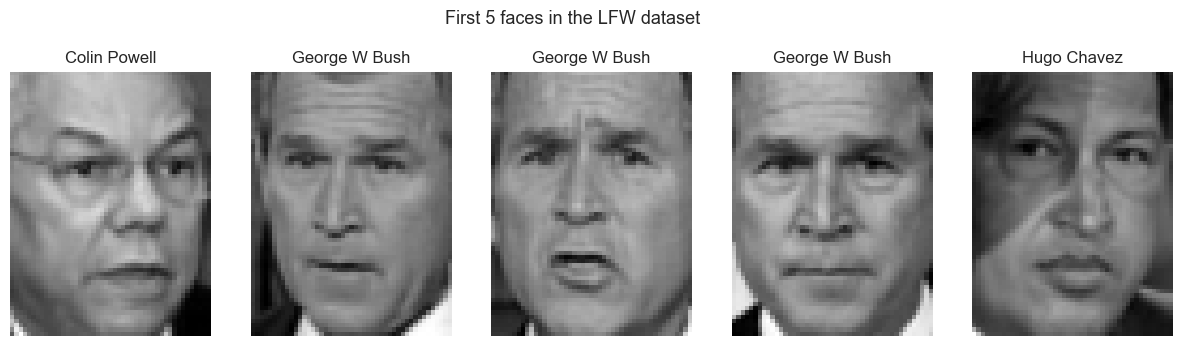

In [15]:
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i in range(5):
    axes[i].imshow(faces.images[i], cmap='gray')
    axes[i].set_title(faces.target_names[faces.target[i]])
    axes[i].axis('off')

plt.suptitle('First 5 faces in the LFW dataset', fontsize=13)
plt.show()

#### Question 2: Train a classification method of your choice to get some predictions. Use cross-validation to get the best results. Remember to select the best parameters!

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

model_original = RandomForestClassifier(n_estimators=100, random_state=42)

# Cross-validation gives a more reliable estimate than one single train/test split.
cv_scores_original = cross_val_score(model_original, X, y, cv=5, scoring='accuracy')

print('Cross-validation scores on original data:', cv_scores_original)
print('Average cross-validation accuracy on original data:', cv_scores_original.mean())

# Fit the model once so we can compare it later with the PCA model.
model_original.fit(X_train, y_train)
y_pred_original = model_original.predict(X_test)
accuracy_original = accuracy_score(y_test, y_pred_original)

print('Final train/test accuracy on original data:', accuracy_original)


Cross-validation scores on original data: [0.61481481 0.60740741 0.5962963  0.59851301 0.64312268]
Average cross-validation accuracy on original data: 0.6120308412501722
Final train/test accuracy on original data: 0.5964391691394659


## 9.4 Model Evaluation

#### Question 3: It's time to reduce our data using PCA! figure out the best amount of principal components and reduce the data.

**Hint: Remember to properly scale your data first!**

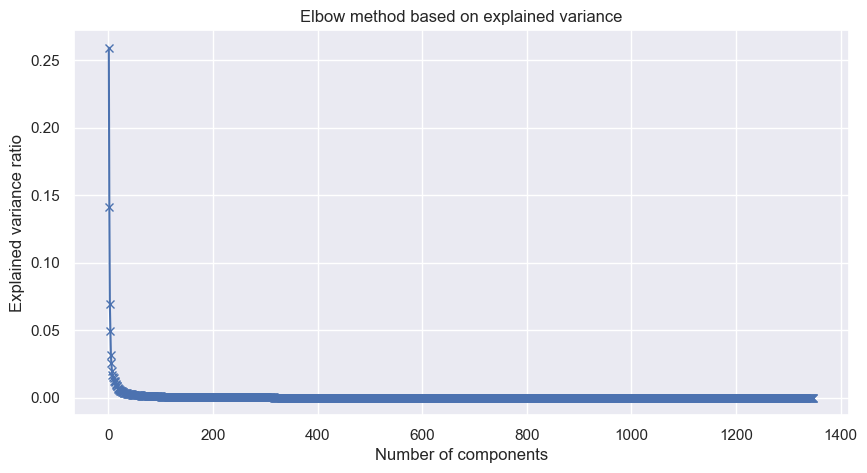

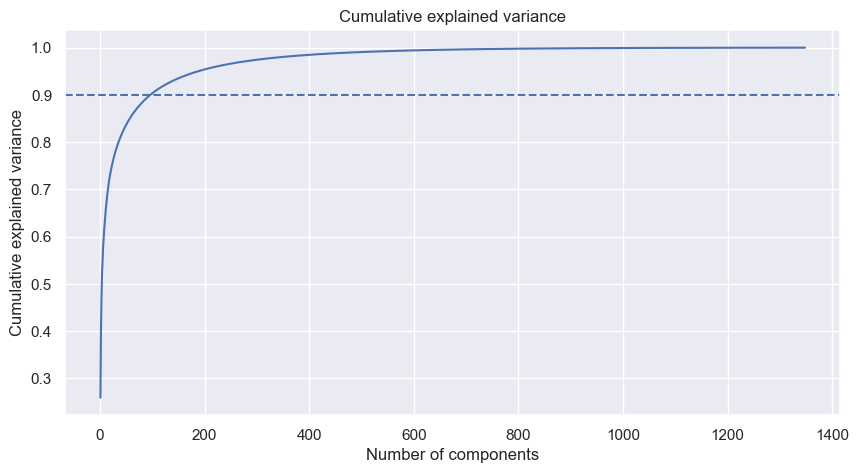

Original shape: (1348, 2914)
Reduced shape: (1348, 97)
Selected number of components: 97
Explained variance kept: 0.90063435


In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit PCA with all possible components to inspect explained variance.
pca_all = PCA()
pca_all.fit(X_scaled)

individual_variance = pca_all.explained_variance_ratio_
cumulative_variance = np.cumsum(individual_variance)

# Elbow plot: individual explained variance per component.
plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(individual_variance) + 1), individual_variance, 'x-')
plt.xlabel('Number of components')
plt.ylabel('Explained variance ratio')
plt.title('Elbow method based on explained variance')
plt.show()

# Cumulative explained variance plot.
plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance)
plt.axhline(y=0.90, linestyle='--')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('Cumulative explained variance')
plt.show()

# Choose the first number of components that keeps at least 90% of the variance.
N_COMPONENTS = np.argmax(cumulative_variance >= 0.90) + 1

pca = PCA(n_components=N_COMPONENTS)
X_pca = pca.fit_transform(X_scaled)

print('Original shape:', X.shape)
print('Reduced shape:', X_pca.shape)
print('Selected number of components:', N_COMPONENTS)
print('Explained variance kept:', pca.explained_variance_ratio_.sum())


#### Question 4: Do you notice something special about the eigenvalues? What is the total sum of all eigenvalues? Play around with models with different amount of components. How does this change? Is this expected? Elaborate based on the meaning of eigenvalue.

In [18]:
print('Total explained variance ratio with all components:')
print(pca_all.explained_variance_ratio_.sum())
print()

print('Explained variance ratio for different numbers of components:')
for n in [10, 25, 50, 75, 100, 150, 200]:
    if n <= min(X_scaled.shape):
        pca_temp = PCA(n_components=n)
        pca_temp.fit(X_scaled)
        print(f'{n:>3} components -> {pca_temp.explained_variance_ratio_.sum():.4f}')


Total explained variance ratio with all components:
0.9999998

Explained variance ratio for different numbers of components:
 10 components -> 0.6417
 25 components -> 0.7607
 50 components -> 0.8363
 75 components -> 0.8769
100 components -> 0.9033
150 components -> 0.9347
200 components -> 0.9535


**Answer:**

When we use all principal components, the sum of the explained variance ratios is **1**, or **100%**. This makes sense because all components together contain all the variance from the original dataset.

When we use fewer components, the sum is lower. That means we keep only part of the information and discard the rest. This is expected because every principal component has its own eigenvalue / explained variance, and PCA orders the components from most important to least important.


#### Question 5: Use PCA and the best amount of components you found earlier to reduce your data. Retrain your model using kfold and compare the accuracy. What do you notice?

In [19]:
model_pca_cv = RandomForestClassifier(n_estimators=100, random_state=42)
cv_scores_pca = cross_val_score(model_pca_cv, X_pca, y, cv=5, scoring='accuracy')

print('Cross-validation scores after PCA:', cv_scores_pca)
print('Average cross-validation accuracy after PCA:', cv_scores_pca.mean())

X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

scaler_final = StandardScaler()
X_train_scaled_final = scaler_final.fit_transform(X_train_final)
X_test_scaled_final = scaler_final.transform(X_test_final)

pca_final = PCA(n_components=N_COMPONENTS)
X_train_pca_final = pca_final.fit_transform(X_train_scaled_final)
X_test_pca_final = pca_final.transform(X_test_scaled_final)

model_pca = RandomForestClassifier(n_estimators=100, random_state=42)
model_pca.fit(X_train_pca_final, y_train_final)

y_pred_pca = model_pca.predict(X_test_pca_final)
accuracy_pca = accuracy_score(y_test_final, y_pred_pca)

print('Accuracy original data:', accuracy_original)
print('Accuracy PCA data:', accuracy_pca)
print('Number of features:', X.shape[1], '->', N_COMPONENTS)


Cross-validation scores after PCA: [0.57407407 0.57777778 0.58888889 0.55390335 0.59851301]
Average cross-validation accuracy after PCA: 0.5786314195236129
Accuracy original data: 0.5964391691394659
Accuracy PCA data: 0.5816023738872403
Number of features: 2914 -> 97


**What do you notice?**

After PCA, the model uses far fewer variables. The accuracy can become slightly lower, similar, or sometimes even slightly better. This is normal: PCA removes information, but it can also remove noise. The important conclusion is that the dataset becomes much smaller while still keeping most of the useful predictive information.


#### Question 6: Your department just got granted some extra budget. You are able to use some more processing power, but still not enough to use the entire dataset. Your boss wants you to create a model that contains 90% of all variance. Create this model and calculate the accuracy as before. By how much did you reduce the size of your dataset?

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca_90 = PCA(n_components=0.90)
X_train_pca_90 = pca_90.fit_transform(X_train_scaled)
X_test_pca_90 = pca_90.transform(X_test_scaled)

print('Number of components kept:', pca_90.n_components_)

rf_pca_90 = RandomForestClassifier(n_estimators=100, random_state=42)
rf_pca_90.fit(X_train_pca_90, y_train)

y_pred_pca_90 = rf_pca_90.predict(X_test_pca_90)
accuracy_pca_90 = accuracy_score(y_test, y_pred_pca_90)

original_features = X.shape[1]
reduced_features = pca_90.n_components_
reduction = 1 - (reduced_features / original_features)

print('Accuracy with PCA keeping 90% variance:', accuracy_pca_90)
print('Original number of features:', original_features)
print('Reduced number of features:', reduced_features)
print('Dataset size reduction:', round(reduction * 100, 2), '%')


Number of components kept: 92
Accuracy with PCA keeping 90% variance: 0.5845697329376854
Original number of features: 2914
Reduced number of features: 92
Dataset size reduction: 96.84 %


For this question, PCA was applied while keeping 90% of the total variance.  
The data was first split into training and test sets. After that, the scaler and PCA were fitted only on the training data and then applied to the test data. This avoids data leakage.

The number of principal components is reduced, while most of the information in the dataset is still preserved. The accuracy can then be compared with the model trained on the original data.

## 9.5 Exercises

#### Question 1: See section 9.3
#### Question 2: See section 9.3
#### Question 3: See section 9.4
#### Question 4: See section 9.4
#### Question 5: See section 9.4
#### Question 6: See section 9.4
#### Question 7: PCA is used to reduce the amount of variables by creating new variables which explain multiple previous ones. By definition, you should get somewhat usable results when reversing this process. Transform your prejected data from question 6 back into the original amount of dimensions and compare the data by looking at the the datapoints of the first face.

In [21]:
X_train_reconstructed_scaled = pca_90.inverse_transform(X_train_pca_90)

X_train_reconstructed = scaler.inverse_transform(X_train_reconstructed_scaled)

original_df = pd.DataFrame(X_train).reset_index(drop=True)
reconstructed_df = pd.DataFrame(X_train_reconstructed)

print("Original data:")
display(original_df.head())

print("Reconstructed data:")
display(reconstructed_df.head())

reconstruction_error = np.mean((original_df.values - reconstructed_df.values) ** 2)

print("Reconstruction error (MSE):", reconstruction_error)

Original data:


,0,1,2,3,4,5,6,7,8,9,...,2904,2905,2906,2907,2908,2909,2910,2911,2912,2913
0,0.471895,0.524183,0.603922,0.660131,0.700654,0.670588,0.633987,0.645752,0.678431,0.694118,...,0.441830,0.407843,0.385621,0.398693,0.402614,0.453595,0.388235,0.418301,0.788235,0.946405
1,0.230065,0.227451,0.231373,0.296732,0.392157,0.448366,0.522876,0.550327,0.575163,0.606536,...,0.346405,0.358170,0.332026,0.267974,0.326797,0.488889,0.739869,0.922876,0.980392,0.955556
2,0.614379,0.619608,0.641830,0.633987,0.664052,0.724183,0.717647,0.666667,0.652288,0.649673,...,0.184314,0.154248,0.135948,0.113725,0.222222,0.537255,0.847059,0.921569,0.913726,0.828758
3,0.117647,0.134641,0.193464,0.367320,0.507190,0.530719,0.513726,0.512418,0.503268,0.504575,...,0.084967,0.104575,0.111111,0.108497,0.117647,0.125490,0.105882,0.105882,0.121569,0.117647
4,0.300654,0.284967,0.457516,0.602614,0.627451,0.628758,0.613072,0.619608,0.639216,0.666667,...,0.226144,0.385621,0.555556,0.620915,0.618301,0.633987,0.650980,0.679739,0.589543,0.214379


Reconstructed data:


,0,1,2,3,4,5,6,7,8,9,...,2904,2905,2906,2907,2908,2909,2910,2911,2912,2913
0,0.450422,0.476140,0.532848,0.614451,0.652645,0.672853,0.685453,0.688646,0.695195,0.683494,...,0.426169,0.381266,0.359420,0.366240,0.393461,0.406085,0.416365,0.531121,0.636441,0.630993
1,0.181448,0.194411,0.199890,0.265068,0.363865,0.456447,0.541784,0.595753,0.618349,0.635396,...,0.382735,0.331707,0.302367,0.339198,0.446989,0.526849,0.573232,0.590798,0.640513,0.702734
2,0.629891,0.626356,0.603314,0.595052,0.641154,0.692578,0.695353,0.673746,0.660954,0.678356,...,0.183624,0.182685,0.194562,0.247209,0.361851,0.517920,0.676492,0.777160,0.820369,0.728476
3,0.169068,0.183698,0.263613,0.339023,0.408649,0.471538,0.480999,0.451541,0.445162,0.457688,...,0.103096,0.046863,0.065234,0.106736,0.156049,0.237217,0.228844,0.120366,0.040989,-0.002188
4,0.333578,0.319547,0.368549,0.495896,0.593524,0.621575,0.605739,0.593432,0.610396,0.638989,...,0.274519,0.383124,0.513938,0.607065,0.687859,0.747389,0.740505,0.602644,0.350731,0.162945


Reconstruction error (MSE): 0.0023559916


The data was reconstructed by first applying the inverse PCA transformation. This brings the data back from the reduced PCA space to the scaled feature space. After that, the inverse transformation of the scaler was applied to return the data to its original scale.

Because PCA kept only 90% of the variance, some information was lost. Therefore, the reconstructed data is not exactly the same as the original data. The reconstruction error measures how large this difference is.

#### Question 8: Now that you have figured out the process of reversing PCA, visualize the reversed data. Compare the reconstructed faces with the original ones and behold the true power of PCA!

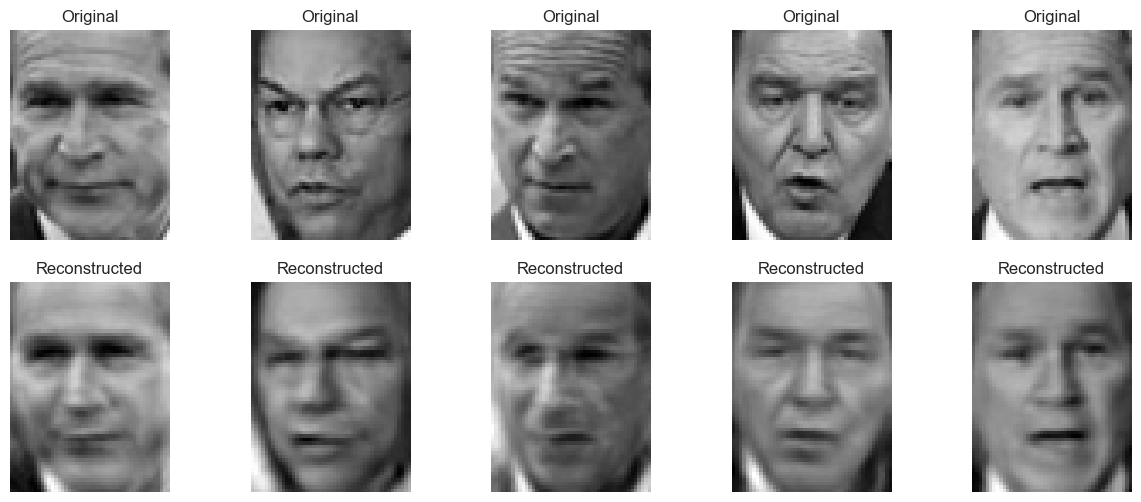

In [22]:
X_reconstructed_scaled = pca_90.inverse_transform(X_train_pca_90)
X_reconstructed = scaler.inverse_transform(X_reconstructed_scaled)

# Correcte image shape (for LFW dataset)
h, w = 62, 47

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i in range(5):
    # Original
    axes[0, i].imshow(X_train[i].reshape(h, w), cmap='gray')
    axes[0, i].set_title("Original")
    axes[0, i].axis('off')
    
    # Reconstructed
    axes[1, i].imshow(X_reconstructed[i].reshape(h, w), cmap='gray')
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis('off')

plt.show()

The original and reconstructed images are visualized to evaluate the effect of PCA. The reconstructed images are obtained by applying the inverse PCA transformation and then reversing the scaling.

Because PCA reduces the dimensionality of the data, some details are lost. This results in reconstructed images that are slightly blurrier or less detailed compared to the original images. However, the main structure of the images is still preserved, showing that PCA effectively compresses the data while retaining important information.

#### Question 9: We talked briefly about how PCA can be used to reduce noise. Assume the 'noisy' data as seen below. Plot the faces as you did before to visually see the noise. What's the best result you can achieve when using PCA to reduce the noise?

In [23]:
# This code creates the faces with noise. Start with the 'noisy' dataframe
# and use PCA to remove the noise once again!
np.random.seed(42)
noisy = np.random.normal(faces.data, 0.1)

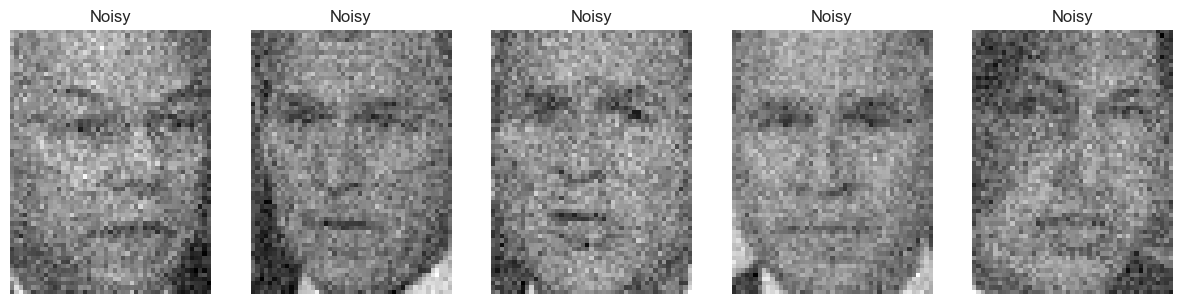

Number of components kept: 629
Explained variance kept: 0.9000355190878259
MSE noisy vs original: 0.010002223274284296
MSE denoised vs original: 0.0076220027910154945


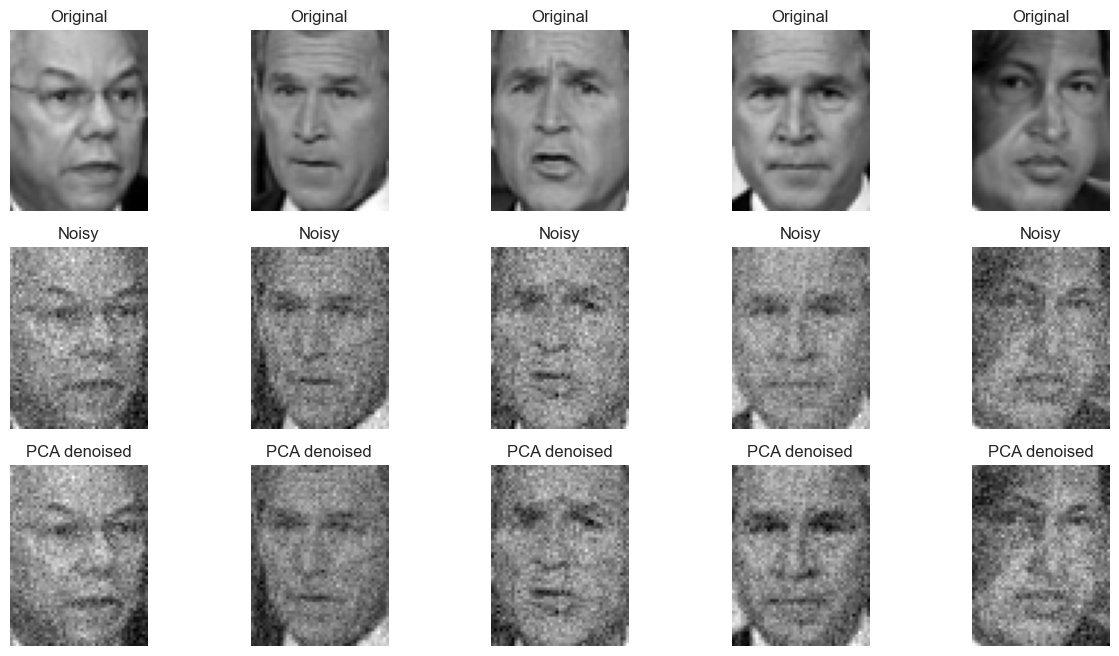

In [24]:
# First visualize the noisy faces.
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i, ax in enumerate(axes):
    ax.imshow(noisy[i].reshape(image_shape), cmap='gray')
    ax.set_title('Noisy')
    ax.axis('off')

plt.show()

# Scale noisy data before PCA.
noisy_scaler = StandardScaler()
noisy_scaled = noisy_scaler.fit_transform(noisy)

# Keep 90% of the variance. This removes some low-variance noise
# while keeping the main structure of the faces.
pca_noise = PCA(n_components=0.90)
noisy_pca = pca_noise.fit_transform(noisy_scaled)
noisy_reconstructed_scaled = pca_noise.inverse_transform(noisy_pca)
denoised = noisy_scaler.inverse_transform(noisy_reconstructed_scaled)

print('Number of components kept:', pca_noise.n_components_)
print('Explained variance kept:', pca_noise.explained_variance_ratio_.sum())
print('MSE noisy vs original:', mean_squared_error(faces.data, noisy))
print('MSE denoised vs original:', mean_squared_error(faces.data, denoised))

# Compare original, noisy and denoised faces.
fig, axes = plt.subplots(3, 5, figsize=(15, 8))

for i in range(5):
    axes[0, i].imshow(faces.data[i].reshape(image_shape), cmap='gray')
    axes[0, i].set_title('Original')
    axes[0, i].axis('off')
    
    axes[1, i].imshow(noisy[i].reshape(image_shape), cmap='gray')
    axes[1, i].set_title('Noisy')
    axes[1, i].axis('off')
    
    axes[2, i].imshow(denoised[i].reshape(image_shape), cmap='gray')
    axes[2, i].set_title('PCA denoised')
    axes[2, i].axis('off')

plt.show()
